In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import struct
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import joblib
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
import tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [7]:
PROJECT_DIR = Path(r"C:\Users\USER\Desktop\MNIST_Digit_Recognition")
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"

In [8]:
DATA_FILES = {
    "train_images": RAW_DATA_DIR / "train-images.idx3-ubyte",
    "train_labels": RAW_DATA_DIR / "train-labels.idx1-ubyte",
    "test_images": RAW_DATA_DIR / "t10k-images.idx3-ubyte",
    "test_labels": RAW_DATA_DIR / "t10k-labels.idx1-ubyte"
}

In [9]:
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
REPORTS_DIR = OUTPUT_DIR / "reports"
RESULTS_DIR = OUTPUT_DIR / "results"

for directory in [FIGURES_DIR, REPORTS_DIR, RESULTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

In [10]:
for file_name, file_path in DATA_FILES.items():
    if not file_path.exists():
        raise FileNotFoundError(
            f"Missing dataset file: {file_name}"
        )

    if not file_path.is_file():
        raise ValueError(
            f"Expected a file but found a directory: {file_name}"
        )

    print(f"{file_name}: Valid")

train_images: Valid
train_labels: Valid
test_images: Valid
test_labels: Valid


In [11]:
for file_name, file_path in DATA_FILES.items():

    file_size_mb = file_path.stat().st_size / (1024 ** 2)

    print(f"{file_name}: {file_size_mb:.2f} MB")

train_images: 44.86 MB
train_labels: 0.06 MB
test_images: 7.48 MB
test_labels: 0.01 MB


In [12]:
with open(DATA_FILES["train_images"], "rb") as file:
    train_image_header = struct.unpack(">IIII", file.read(16))

with open(DATA_FILES["train_labels"], "rb") as file:
    train_label_header = struct.unpack(">II", file.read(8))

with open(DATA_FILES["test_images"], "rb") as file:
    test_image_header = struct.unpack(">IIII", file.read(16))

with open(DATA_FILES["test_labels"], "rb") as file:
    test_label_header = struct.unpack(">II", file.read(8))


print("Training Image Header:", train_image_header)
print("Training Label Header:", train_label_header)

print("Testing Image Header:", test_image_header)
print("Testing Label Header:", test_label_header)

Training Image Header: (2051, 60000, 28, 28)
Training Label Header: (2049, 60000)
Testing Image Header: (2051, 10000, 28, 28)
Testing Label Header: (2049, 10000)


In [13]:
def load_mnist_images(file_path):
    with open(file_path, "rb") as file:
        magic_number, num_images, rows, cols = struct.unpack(
            ">IIII", file.read(16)
        )
        if magic_number != 2051:
            raise ValueError("Invalid image file format")
        images = np.frombuffer(file.read(), dtype=np.uint8)
        images = images.reshape(num_images, rows, cols)
    return images

In [14]:
def load_mnist_labels(file_path):
    with open(file_path, "rb") as file:
        magic_number, num_labels = struct.unpack(
            ">II", file.read(8)
        )
        if magic_number != 2049:
            raise ValueError("Invalid label file format")
        labels = np.frombuffer(file.read(), dtype=np.uint8)

    return labels

In [15]:
X_train = load_mnist_images(DATA_FILES["train_images"])
y_train = load_mnist_labels(DATA_FILES["train_labels"])
X_test = load_mnist_images(DATA_FILES["test_images"])
y_test = load_mnist_labels(DATA_FILES["test_labels"])

print("MNIST dataset loaded successfully!")

MNIST dataset loaded successfully!


In [16]:
print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)
print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

Training Images: (60000, 28, 28)
Training Labels: (60000,)
Testing Images: (10000, 28, 28)
Testing Labels: (10000,)


In [17]:
assert len(X_train) == len(y_train), "Training data mismatch"
assert len(X_test) == len(y_test), "Testing data mismatch"
assert X_train.shape[1:] == (28, 28), "Invalid training image dimensions"
assert X_test.shape[1:] == (28, 28), "Invalid testing image dimensions"
assert np.isin(y_train, range(10)).all(), "Invalid training labels"
assert np.isin(y_test, range(10)).all(), "Invalid testing labels"
print("All data integrity checks passed!")

All data integrity checks passed!


In [18]:
print("Image Data Type:", X_train.dtype)
print("Label Data Type:", y_train.dtype)
print("Minimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())
print("Unique Labels:", np.unique(y_train))

Image Data Type: uint8
Label Data Type: uint8
Minimum Pixel Value: 0
Maximum Pixel Value: 255
Unique Labels: [0 1 2 3 4 5 6 7 8 9]


In [19]:
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("Image Dimensions:", X_train.shape[1:])
print("Number of Classes:", len(np.unique(y_train)))

print("Training Memory Usage:", X_train.nbytes / (1024 ** 2), "MB")
print("Testing Memory Usage:", X_test.nbytes / (1024 ** 2), "MB")

Training Samples: 60000
Testing Samples: 10000
Image Dimensions: (28, 28)
Number of Classes: 10
Training Memory Usage: 44.86083984375 MB
Testing Memory Usage: 7.476806640625 MB


In [20]:
dataset_overview = pd.DataFrame({
    "Metric": [
        "Training Samples",
        "Testing Samples",
        "Image Height",
        "Image Width",
        "Number of Classes",
        "Training Memory (MB)",
        "Testing Memory (MB)"
    ],
    "Value": [
        X_train.shape[0],
        X_test.shape[0],
        X_train.shape[1],
        X_train.shape[2],
        len(np.unique(y_train)),
        X_train.nbytes / (1024 ** 2),
        X_test.nbytes / (1024 ** 2)
    ]
})

dataset_overview.to_csv(
    REPORTS_DIR / "dataset_overview.csv",
    index=False
)

dataset_overview

,Metric,Value
0,Training Samples,60000.000000
1,Testing Samples,10000.000000
2,Image Height,28.000000
3,Image Width,28.000000
4,Number of Classes,10.000000
5,Training Memory (MB),44.860840
6,Testing Memory (MB),7.476807


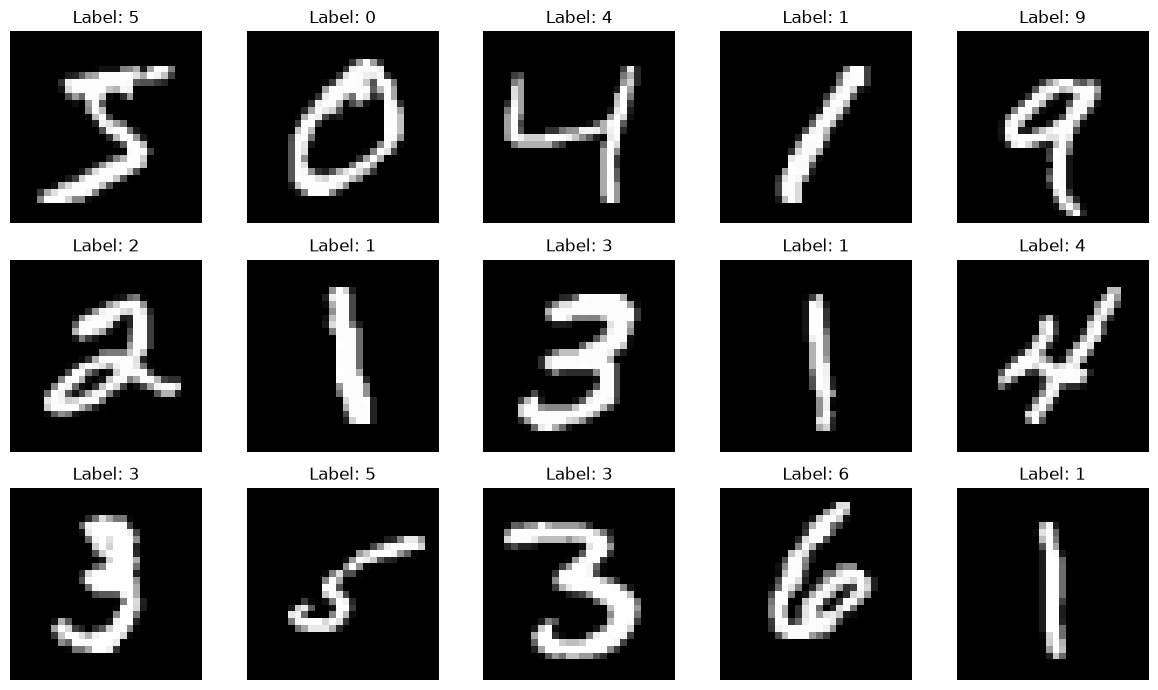

In [21]:
fig, axes = plt.subplots(3, 5, figsize=(12, 7))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i], cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "sample_digits.png", dpi=300, bbox_inches="tight")
plt.show()

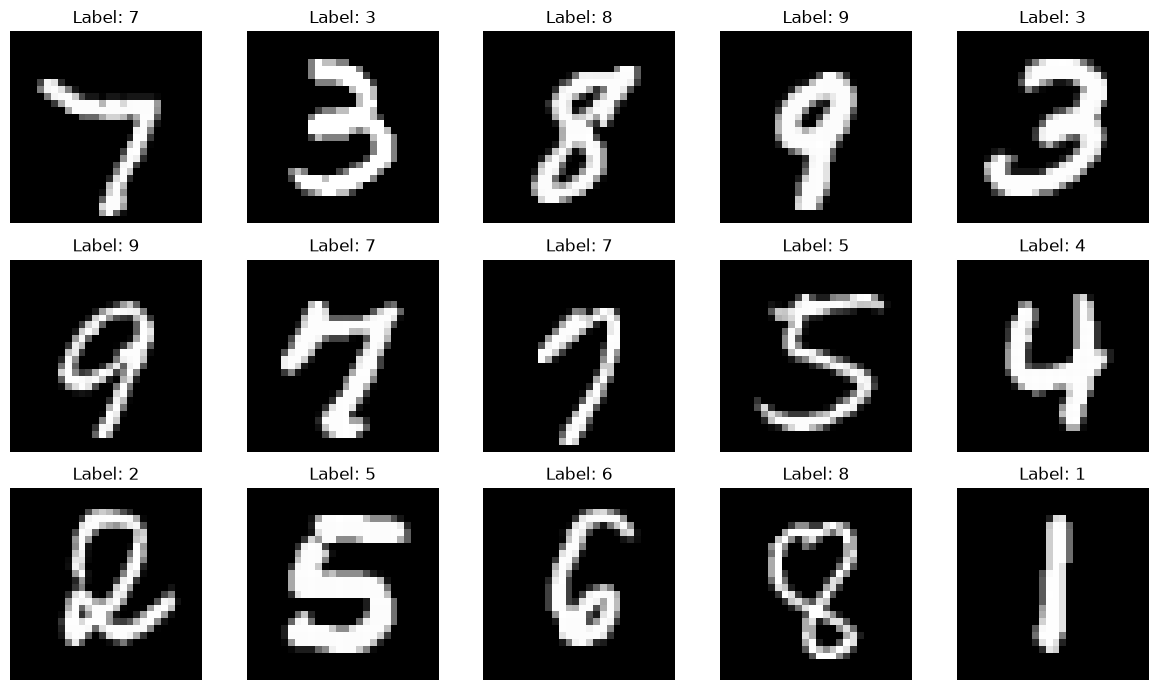

In [22]:
np.random.seed(42)

random_indices = np.random.choice(
    len(X_train), 15, replace=False
)

fig, axes = plt.subplots(3, 5, figsize=(12, 7))

for i, ax in enumerate(axes.flat):
    index = random_indices[i]
    ax.imshow(X_train[index], cmap="gray")
    ax.set_title(f"Label: {y_train[index]}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "random_samples.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
class_counts = pd.Series(y_train).value_counts().sort_index()

distribution_df = pd.DataFrame({
    "Count": class_counts,
    "Percentage": (class_counts / len(y_train)) * 100
})

distribution_df

,Count,Percentage
0,5923,9.871667
1,6742,11.236667
2,5958,9.930000
3,6131,10.218333
4,5842,9.736667
5,5421,9.035000
6,5918,9.863333
7,6265,10.441667
8,5851,9.751667
9,5949,9.915000


In [24]:
distribution_df.to_csv(
    REPORTS_DIR / "class_distribution.csv",
    index_label="Digit"
)

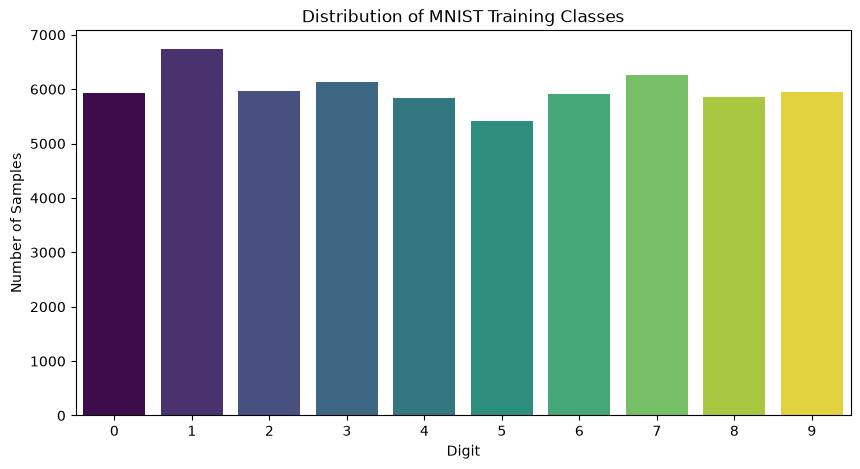

In [25]:
plt.figure(figsize=(10, 5))

sns.countplot(
    x=y_train,
    hue=y_train,
    palette="viridis",
    legend=False
)

plt.title("Distribution of MNIST Training Classes")
plt.xlabel("Digit")
plt.ylabel("Number of Samples")

plt.savefig(
    FIGURES_DIR / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

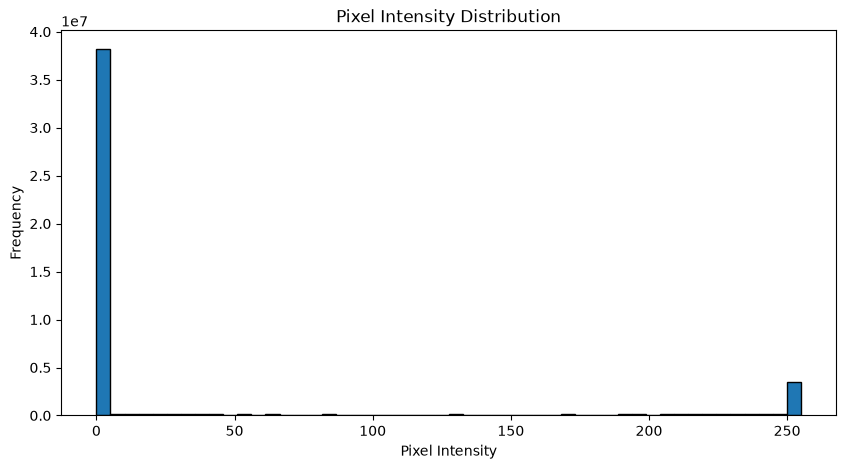

In [26]:
plt.figure(figsize=(10, 5))

plt.hist(
    X_train.ravel(),
    bins=50,
    edgecolor="black"
)

plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.savefig(
    FIGURES_DIR / "pixel_intensity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
pixel_statistics = pd.DataFrame({
    "Metric": [
        "Minimum",
        "Maximum",
        "Mean",
        "Standard Deviation",
        "Median"
    ],
    "Value": [
        X_train.min(),
        X_train.max(),
        X_train.mean(),
        X_train.std(),
        np.median(X_train)
    ]
})

pixel_statistics.to_csv(
    REPORTS_DIR / "pixel_statistics.csv",
    index=False
)

pixel_statistics

,Metric,Value
0,Minimum,0.000000
1,Maximum,255.000000
2,Mean,33.318421
3,Standard Deviation,78.567490
4,Median,0.000000


In [28]:
print("Training Images contain NaN:", np.isnan(X_train).any())
print("Training Labels contain NaN:", np.isnan(y_train).any())

print("Testing Images contain NaN:", np.isnan(X_test).any())
print("Testing Labels contain NaN:", np.isnan(y_test).any())

Training Images contain NaN: False
Training Labels contain NaN: False
Testing Images contain NaN: False
Testing Labels contain NaN: False


In [29]:
unique_images = np.unique(
    X_train.reshape(len(X_train), -1),
    axis=0
)

duplicate_count = len(X_train) - len(unique_images)

print("Total Training Images:", len(X_train))
print("Unique Training Images:", len(unique_images))
print("Duplicate Images:", duplicate_count)

Total Training Images: 60000
Unique Training Images: 60000
Duplicate Images: 0


In [30]:
duplicate_report = []
for digit in range(10):
    digit_images = X_train[y_train == digit]
    unique_count = len(np.unique(
        digit_images.reshape(len(digit_images), -1),
        axis=0
    ))
    duplicate_report.append({
        "Digit": digit,
        "Total Images": len(digit_images),
        "Unique Images": unique_count,
        "Duplicate Images": len(digit_images) - unique_count
    })
duplicate_df = pd.DataFrame(duplicate_report)

duplicate_df.to_csv(
    REPORTS_DIR / "duplicate_analysis.csv",
    index=False
)
duplicate_df

,Digit,Total Images,Unique Images,Duplicate Images
0,0,5923,5923,0
1,1,6742,6742,0
2,2,5958,5958,0
3,3,6131,6131,0
4,4,5842,5842,0
5,5,5421,5421,0
6,6,5918,5918,0
7,7,6265,6265,0
8,8,5851,5851,0
9,9,5949,5949,0


In [31]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Missing Values in Images",
        "Missing Values in Labels",
        "Duplicate Training Images",
        "Unique Training Images",
        "Pixel Mean",
        "Pixel Standard Deviation"
    ],
    "Value": [
        np.isnan(X_train).sum(),
        np.isnan(y_train).sum(),
        duplicate_count,
        len(unique_images),
        X_train.mean(),
        X_train.std()
    ]
})

eda_summary.to_csv(
    REPORTS_DIR / "eda_summary.csv",
    index=False
)

eda_summary

,Metric,Value
0,Missing Values in Images,0.000000
1,Missing Values in Labels,0.000000
2,Duplicate Training Images,0.000000
3,Unique Training Images,60000.000000
4,Pixel Mean,33.318421
5,Pixel Standard Deviation,78.567490


In [32]:
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

print("Training Shape:", X_train_flat.shape)
print("Testing Shape:", X_test_flat.shape)

Training Shape: (60000, 784)
Testing Shape: (10000, 784)


In [33]:
X_train_normalized = X_train_flat.astype("float32") / 255.0
X_test_normalized = X_test_flat.astype("float32") / 255.0

print("Minimum:", X_train_normalized.min())
print("Maximum:", X_train_normalized.max())
print("Mean:", X_train_normalized.mean())

Minimum: 0.0
Maximum: 1.0
Mean: 0.13066047


In [34]:
X_train_cnn = X_train.astype("float32") / 255.0
X_test_cnn = X_test.astype("float32") / 255.0

X_train_cnn = np.expand_dims(X_train_cnn, axis=-1)
X_test_cnn = np.expand_dims(X_test_cnn, axis=-1)

print("CNN Training Shape:", X_train_cnn.shape)
print("CNN Testing Shape:", X_test_cnn.shape)

CNN Training Shape: (60000, 28, 28, 1)
CNN Testing Shape: (10000, 28, 28, 1)


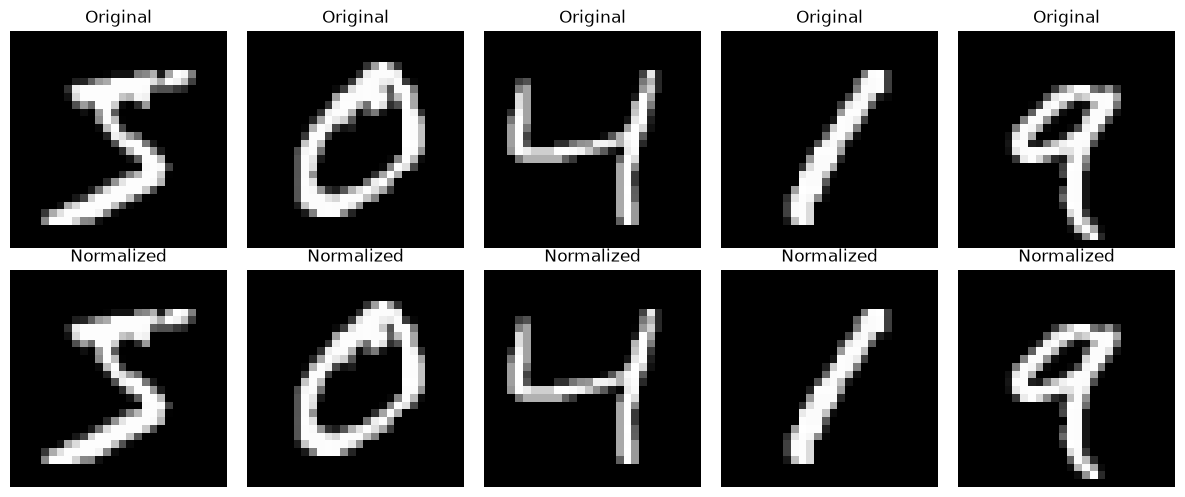

In [35]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i in range(5):
    axes[0, i].imshow(X_train[i], cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(X_train_normalized[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Normalized")
    axes[1, i].axis("off")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "normalization_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [36]:
assert X_train_normalized.shape == (60000, 784)
assert X_test_normalized.shape == (10000, 784)

assert X_train_cnn.shape == (60000, 28, 28, 1)
assert X_test_cnn.shape == (10000, 28, 28, 1)

assert X_train_normalized.min() >= 0
assert X_train_normalized.max() <= 1

assert X_test_normalized.min() >= 0
assert X_test_normalized.max() <= 1

print("Preprocessing validation completed successfully!")

Preprocessing validation completed successfully!


In [37]:
X_train_split, X_val, y_train_split, y_val = train_test_split(
    X_train_normalized,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

print("Training Set:", X_train_split.shape)
print("Validation Set:", X_val.shape)
print("Training Labels:", y_train_split.shape)
print("Validation Labels:", y_val.shape)

Training Set: (54000, 784)
Validation Set: (6000, 784)
Training Labels: (54000,)
Validation Labels: (6000,)


In [38]:
logistic_model = LogisticRegression(
    max_iter=500,
    solver="lbfgs",
    random_state=42
)

In [39]:
logistic_model.fit(
    X_train_split,
    y_train_split
)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",500
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbf

In [40]:
print("Number of Iterations:", logistic_model.n_iter_)
print("Maximum Iterations:", logistic_model.max_iter)

Number of Iterations: [262]
Maximum Iterations: 500


In [41]:
y_val_pred_lr = logistic_model.predict(X_val)

print("Predictions:", y_val_pred_lr[:20])
print("Actual Labels:", y_val[:20])

Predictions: [1 9 3 4 6 5 0 8 5 1 0 5 2 9 3 0 0 6 0 9]
Actual Labels: [1 9 3 4 6 5 0 8 5 1 0 5 2 9 5 0 0 6 0 9]


In [42]:
lr_accuracy = accuracy_score(y_val, y_val_pred_lr)
lr_precision = precision_score(
    y_val, y_val_pred_lr, average="weighted"
)
lr_recall = recall_score(
    y_val, y_val_pred_lr, average="weighted"
)
lr_f1 = f1_score(
    y_val, y_val_pred_lr, average="weighted"
)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy:", lr_accuracy)
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1 Score:", lr_f1)

Logistic Regression Results
---------------------------
Accuracy: 0.9221666666666667
Precision: 0.9220195153249371
Recall: 0.9221666666666667
F1 Score: 0.9220109959569813


In [43]:
lr_report = classification_report(
    y_val,
    y_val_pred_lr,
    output_dict=True
)

lr_report_df = pd.DataFrame(lr_report).transpose()

lr_report_df.to_csv(
    REPORTS_DIR / "logistic_regression_classification_report.csv"
)

lr_report_df

,precision,recall,f1-score,support
0,0.945724,0.971284,0.958333,592.000000
1,0.952243,0.976261,0.964103,674.000000
2,0.919721,0.884228,0.901625,596.000000
3,0.895935,0.898858,0.897394,613.000000
4,0.934370,0.926370,0.930353,584.000000
5,0.902072,0.883764,0.892824,542.000000
6,0.942470,0.940878,0.941674,592.000000
7,0.937600,0.934609,0.936102,627.000000
8,0.878632,0.878632,0.878632,585.000000
9,0.905316,0.915966,0.910610,595.000000


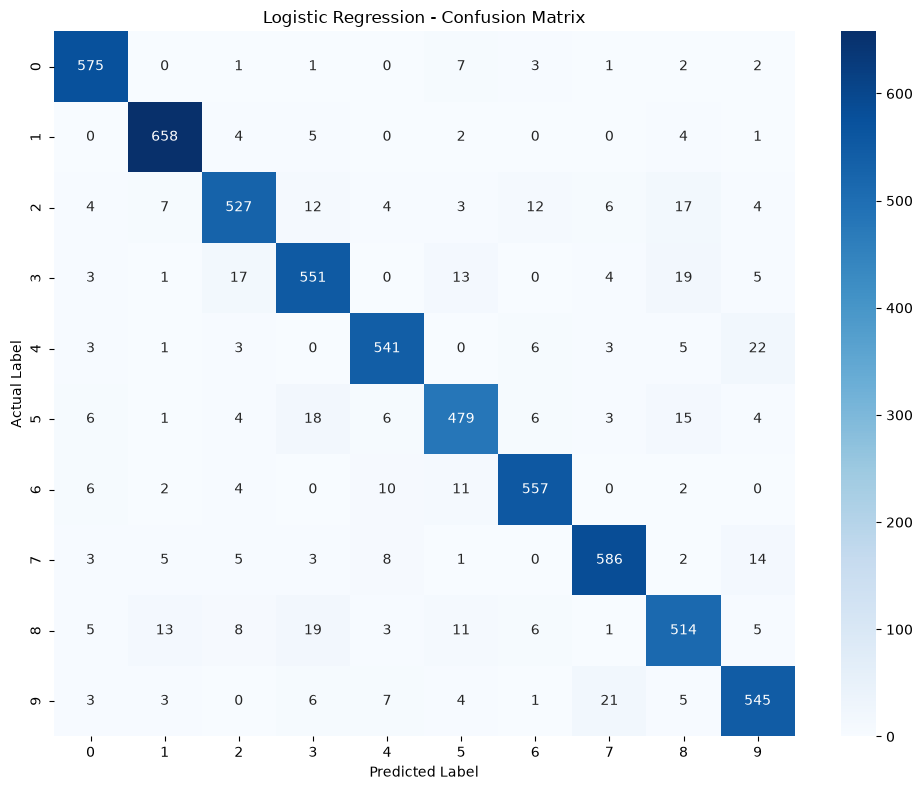

In [44]:
lr_cm = confusion_matrix(y_val, y_val_pred_lr)

plt.figure(figsize=(10, 8))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [140]:
joblib.dump(
    logistic_model,
    PROJECT_DIR / "models" / "logistic_regression.pkl"
)

['C:\\Users\\USER\\Desktop\\MNIST_Digit_Recognition\\models\\logistic_regression.pkl']

In [45]:
knn_model = KNeighborsClassifier(
    n_neighbors=3,
    weights="distance",
    n_jobs=-1
)

In [46]:
knn_model.fit(
    X_train_split,
    y_train_split
)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",-1
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[uint8](10,)","[0,1,2,...,7,8,9]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [47]:
y_val_pred_knn = knn_model.predict(X_val)

print("Predictions:", y_val_pred_knn[:20])
print("Actual Labels:", y_val[:20])

Predictions: [1 9 3 4 6 5 0 8 5 1 0 5 2 9 5 0 0 6 0 9]
Actual Labels: [1 9 3 4 6 5 0 8 5 1 0 5 2 9 5 0 0 6 0 9]


In [48]:
knn_accuracy = accuracy_score(y_val, y_val_pred_knn)

knn_precision = precision_score(
    y_val,
    y_val_pred_knn,
    average="weighted"
)

knn_recall = recall_score(
    y_val,
    y_val_pred_knn,
    average="weighted"
)

knn_f1 = f1_score(
    y_val,
    y_val_pred_knn,
    average="weighted"
)

print("KNN Results")
print("---------------------------")
print("Accuracy:", knn_accuracy)
print("Precision:", knn_precision)
print("Recall:", knn_recall)
print("F1 Score:", knn_f1)

KNN Results
---------------------------
Accuracy: 0.9723333333333334
Precision: 0.9725270208519681
Recall: 0.9723333333333334
F1 Score: 0.9722902701738212


In [49]:
knn_report = classification_report(
    y_val,
    y_val_pred_knn,
    output_dict=True
)

knn_report_df = pd.DataFrame(knn_report).transpose()

knn_report_df.to_csv(
    REPORTS_DIR / "knn_classification_report.csv"
)

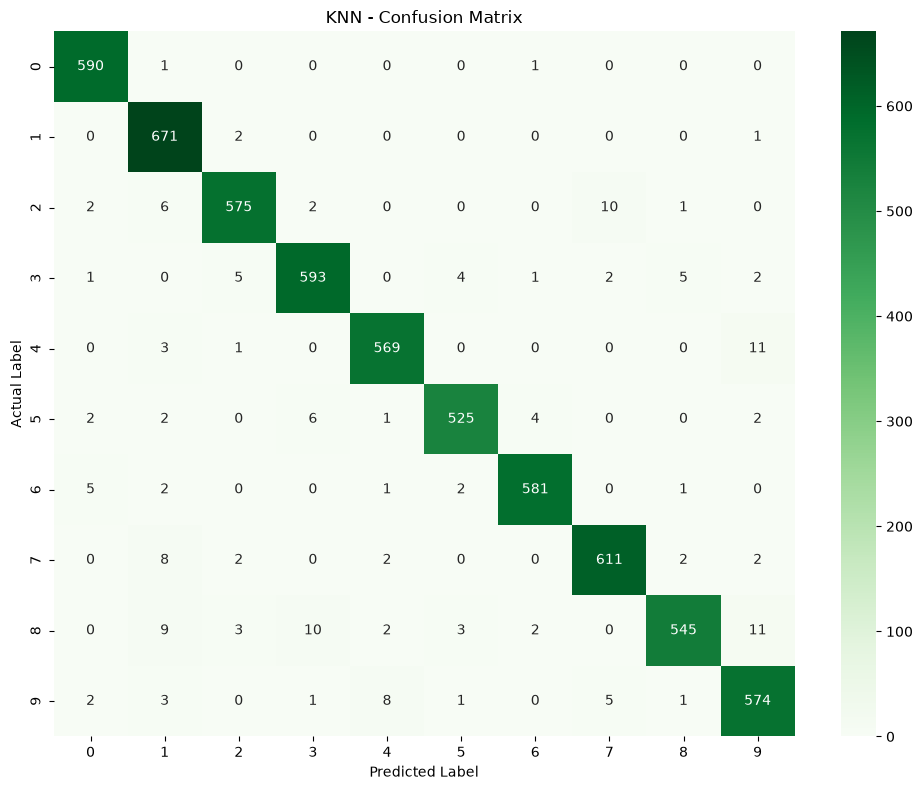

In [50]:
knn_cm = confusion_matrix(y_val, y_val_pred_knn)

plt.figure(figsize=(10, 8))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "knn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:
joblib.dump(
    knn_model,
    PROJECT_DIR / "models" / "knn_model.pkl"
)

['C:\\Users\\USER\\Desktop\\MNIST_Digit_Recognition\\models\\knn_model.pkl']

In [52]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [53]:
rf_model.fit(
    X_train_split,
    y_train_split
)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [54]:
y_val_pred_rf = rf_model.predict(X_val)

print("Predictions:", y_val_pred_rf[:20])
print("Actual Labels:", y_val[:20])

Predictions: [1 9 3 4 6 5 0 8 5 1 0 5 2 9 5 0 0 6 0 9]
Actual Labels: [1 9 3 4 6 5 0 8 5 1 0 5 2 9 5 0 0 6 0 9]


In [55]:
rf_accuracy = accuracy_score(y_val, y_val_pred_rf)

rf_precision = precision_score(
    y_val,
    y_val_pred_rf,
    average="weighted"
)

rf_recall = recall_score(
    y_val,
    y_val_pred_rf,
    average="weighted"
)

rf_f1 = f1_score(
    y_val,
    y_val_pred_rf,
    average="weighted"
)

print("Random Forest Results")
print("---------------------------")
print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1 Score:", rf_f1)

Random Forest Results
---------------------------
Accuracy: 0.9658333333333333
Precision: 0.9658611280099476
Recall: 0.9658333333333333
F1 Score: 0.9658200970042059


In [56]:
rf_report = classification_report(
    y_val,
    y_val_pred_rf,
    output_dict=True
)

rf_report_df = pd.DataFrame(rf_report).transpose()

rf_report_df.to_csv(
    REPORTS_DIR / "random_forest_classification_report.csv"
)

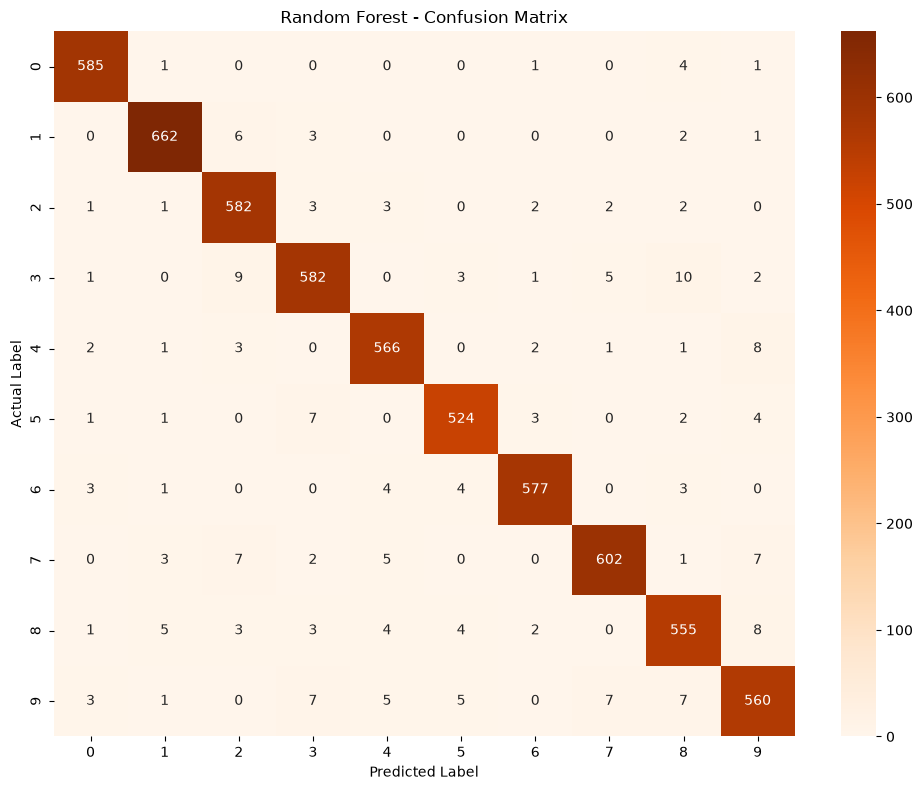

In [57]:
rf_cm = confusion_matrix(y_val, y_val_pred_rf)

plt.figure(figsize=(10, 8))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [141]:
joblib.dump(
    rf_model,
    PROJECT_DIR / "models" / "random_forest.pkl"
)

['C:\\Users\\USER\\Desktop\\MNIST_Digit_Recognition\\models\\random_forest.pkl']

In [58]:
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": lr_accuracy,
        "Precision": lr_precision,
        "Recall": lr_recall,
        "F1 Score": lr_f1
    },
    {
        "Model": "KNN",
        "Accuracy": knn_accuracy,
        "Precision": knn_precision,
        "Recall": knn_recall,
        "F1 Score": knn_f1
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1 Score": rf_f1
    }
])

model_comparison.to_csv(
    RESULTS_DIR / "model_comparison.csv",
    index=False
)

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.922167,0.922020,0.922167,0.922011
1,KNN,0.972333,0.972527,0.972333,0.972290
2,Random Forest,0.965833,0.965861,0.965833,0.965820


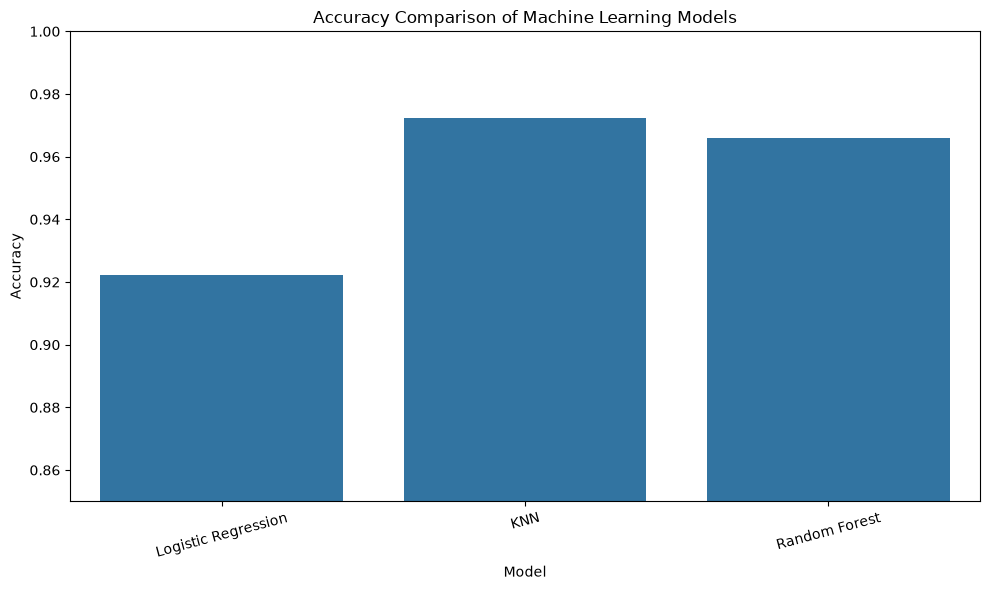

In [59]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Machine Learning Models")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0.85, 1.0)
plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "model_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

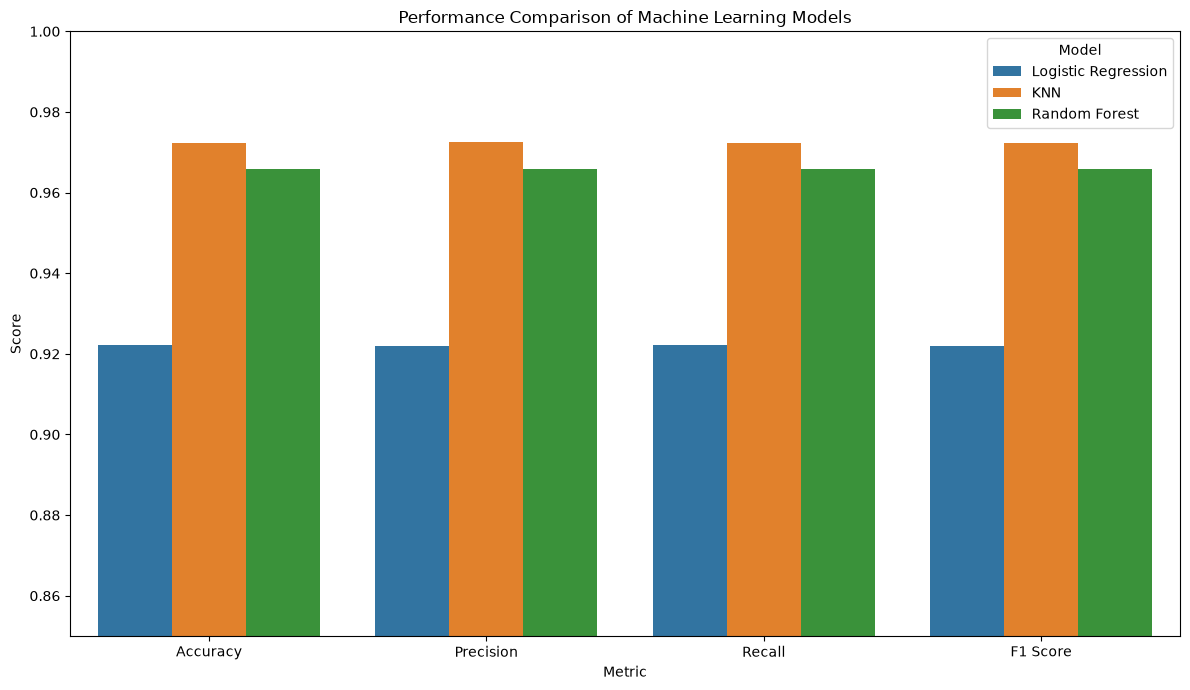

In [60]:
comparison_melted = model_comparison.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=comparison_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Performance Comparison of Machine Learning Models")
plt.ylim(0.85, 1.0)
plt.legend(title="Model")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "all_metrics_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [61]:
tf.random.set_seed(42)
np.random.seed(42)

In [62]:
ann_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [63]:
ann_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [64]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [65]:
ann_history = ann_model.fit(
    X_train_split,
    y_train_split,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9175 - loss: 0.2839 - val_accuracy: 0.9585 - val_loss: 0.1409
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9678 - loss: 0.1090 - val_accuracy: 0.9680 - val_loss: 0.1068
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9796 - loss: 0.0700 - val_accuracy: 0.9725 - val_loss: 0.0908
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9857 - loss: 0.0483 - val_accuracy: 0.9737 - val_loss: 0.0881
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9899 - loss: 0.0342 - val_accuracy: 0.9737 - val_loss: 0.0940
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9929 - loss: 0.0246 - val_accuracy: 0.9730 - val_loss: 0.1047
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9941 - loss: 0.0198 - val_accuracy: 0.9763 - val_loss: 0.0947


In [66]:
print("Completed Epochs:", len(ann_history.history["accuracy"]))
print("Best Validation Accuracy:", max(ann_history.history["val_accuracy"]))
print("Best Validation Loss:", min(ann_history.history["val_loss"]))

Completed Epochs: 7
Best Validation Accuracy: 0.9763333201408386
Best Validation Loss: 0.08814924210309982


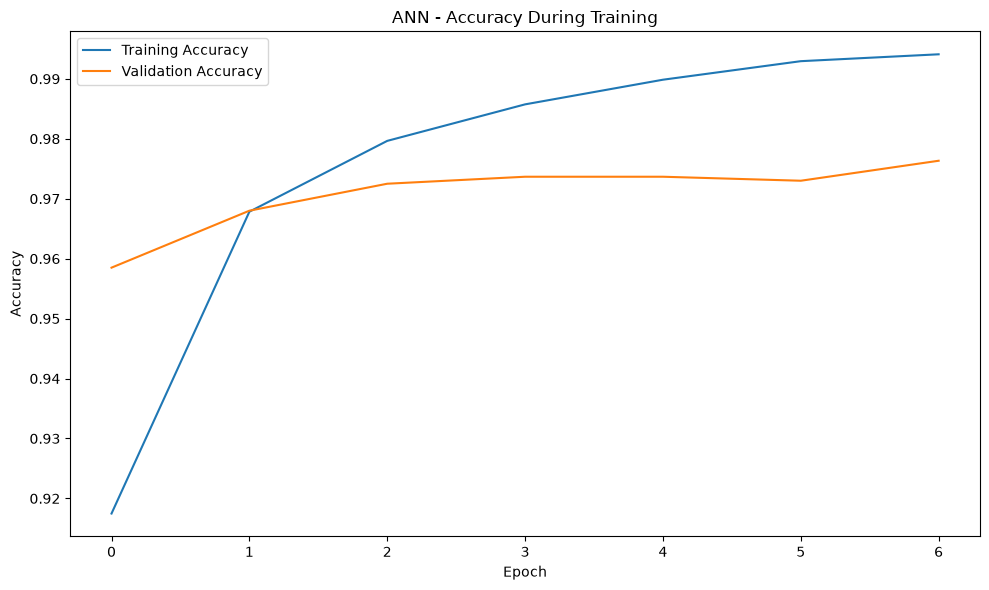

In [67]:
history_df = pd.DataFrame(ann_history.history)

plt.figure(figsize=(10, 6))

plt.plot(history_df["accuracy"], label="Training Accuracy")
plt.plot(history_df["val_accuracy"], label="Validation Accuracy")

plt.title("ANN - Accuracy During Training")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "ann_accuracy_history.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

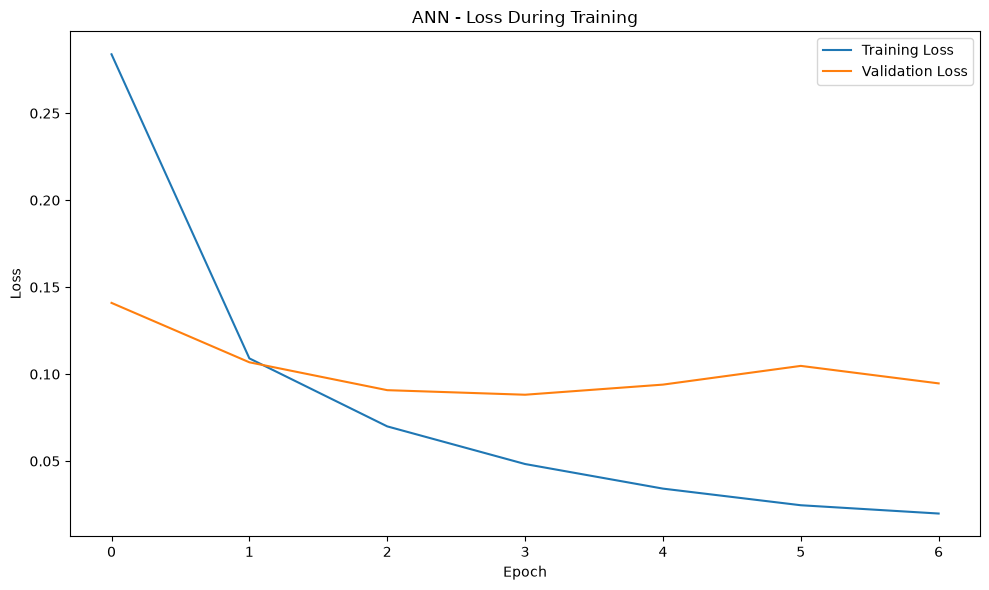

In [68]:
plt.figure(figsize=(10, 6))

plt.plot(history_df["loss"], label="Training Loss")
plt.plot(history_df["val_loss"], label="Validation Loss")

plt.title("ANN - Loss During Training")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "ann_loss_history.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [69]:
y_val_pred_ann_prob = ann_model.predict(X_val)

y_val_pred_ann = np.argmax(
    y_val_pred_ann_prob,
    axis=1
)

ann_accuracy = accuracy_score(y_val, y_val_pred_ann)

ann_precision = precision_score(
    y_val, y_val_pred_ann, average="weighted"
)

ann_recall = recall_score(
    y_val, y_val_pred_ann, average="weighted"
)

ann_f1 = f1_score(
    y_val, y_val_pred_ann, average="weighted"
)

print("ANN Results")
print("---------------------------")
print("Accuracy:", ann_accuracy)
print("Precision:", ann_precision)
print("Recall:", ann_recall)
print("F1 Score:", ann_f1)

188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 958us/step
ANN Results
---------------------------
Accuracy: 0.9736666666666667
Precision: 0.9737831083195365
Recall: 0.9736666666666667
F1 Score: 0.9736671344949467


In [70]:
ann_report = classification_report(
    y_val,
    y_val_pred_ann,
    output_dict=True
)

ann_report_df = pd.DataFrame(ann_report).transpose()

ann_report_df.to_csv(
    REPORTS_DIR / "ann_classification_report.csv"
)

In [71]:
ann_model.save(
    PROJECT_DIR / "models" / "ann_model.keras"
)

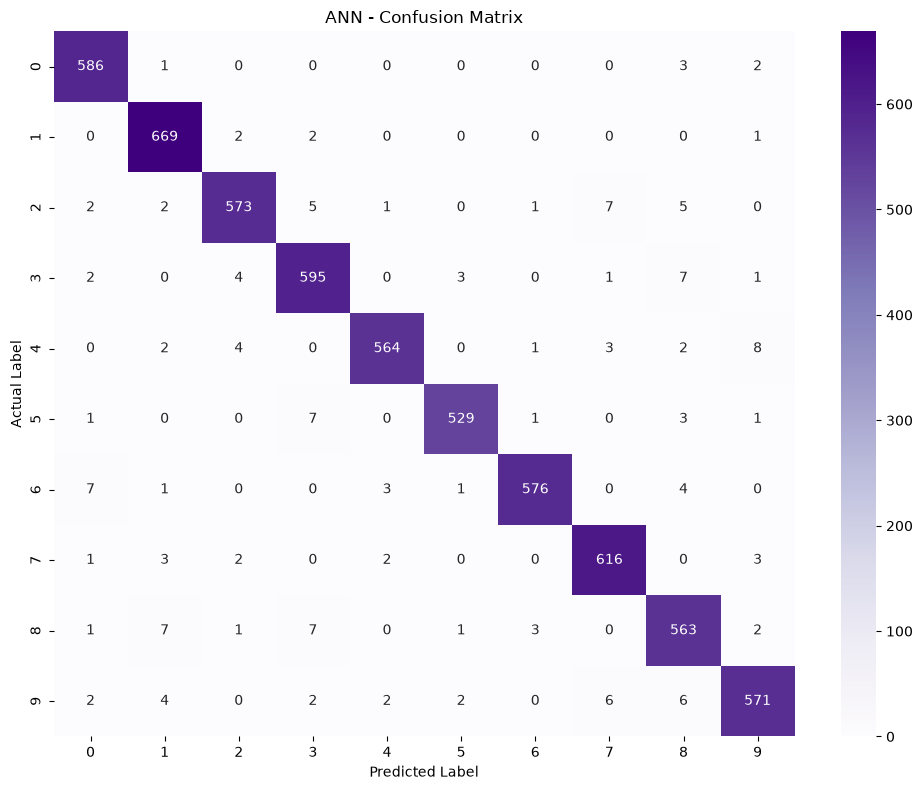

In [72]:
ann_cm = confusion_matrix(y_val, y_val_pred_ann)

plt.figure(figsize=(10, 8))

sns.heatmap(
    ann_cm,
    annot=True,
    fmt="d",
    cmap="Purples"
)

plt.title("ANN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "ann_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [73]:
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": lr_accuracy,
        "Precision": lr_precision,
        "Recall": lr_recall,
        "F1 Score": lr_f1
    },
    {
        "Model": "KNN",
        "Accuracy": knn_accuracy,
        "Precision": knn_precision,
        "Recall": knn_recall,
        "F1 Score": knn_f1
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1 Score": rf_f1
    },
    {
        "Model": "ANN",
        "Accuracy": ann_accuracy,
        "Precision": ann_precision,
        "Recall": ann_recall,
        "F1 Score": ann_f1
    }
])

model_comparison.to_csv(
    RESULTS_DIR / "model_comparison.csv",
    index=False
)

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.922167,0.922020,0.922167,0.922011
1,KNN,0.972333,0.972527,0.972333,0.972290
2,Random Forest,0.965833,0.965861,0.965833,0.965820
3,ANN,0.973667,0.973783,0.973667,0.973667


In [74]:
X_train_cnn_split, X_val_cnn, y_train_cnn_split, y_val_cnn = train_test_split(
    X_train_cnn,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

print("Training Images:", X_train_cnn_split.shape)
print("Validation Images:", X_val_cnn.shape)

Training Images: (54000, 28, 28, 1)
Validation Images: (6000, 28, 28, 1)


In [75]:
cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(10, activation="softmax")
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [76]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [77]:
cnn_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [78]:
cnn_history = cnn_model.fit(
    X_train_cnn_split,
    y_train_cnn_split,
    validation_data=(X_val_cnn, y_val_cnn),
    epochs=15,
    batch_size=128,
    callbacks=[cnn_early_stopping],
    verbose=1
)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.9157 - loss: 0.2747 - val_accuracy: 0.9792 - val_loss: 0.0775
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9770 - loss: 0.0761 - val_accuracy: 0.9825 - val_loss: 0.0603
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9844 - loss: 0.0530 - val_accuracy: 0.9860 - val_loss: 0.0521
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9869 - loss: 0.0428 - val_accuracy: 0.9863 - val_loss: 0.0447
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9891 - loss: 0.0345 - val_accuracy: 0.9870 - val_loss: 0.0470
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9909 - loss: 0.0299 - val_accuracy: 0.9885 - val_loss: 0.0423
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9925 - loss: 0.0233 - val_accuracy: 0.9882 - val_loss: 0.0444
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9931 - loss: 0.0214 - val_accu

In [79]:
print("Completed Epochs:", len(cnn_history.history["accuracy"]))
print("Best Validation Accuracy:", max(cnn_history.history["val_accuracy"]))
print("Best Validation Loss:", min(cnn_history.history["val_loss"]))

Completed Epochs: 11
Best Validation Accuracy: 0.9898333549499512
Best Validation Loss: 0.03905600309371948


In [80]:
y_val_pred_cnn_prob = cnn_model.predict(X_val_cnn)

y_val_pred_cnn = np.argmax(
    y_val_pred_cnn_prob,
    axis=1
)

cnn_accuracy = accuracy_score(y_val_cnn, y_val_pred_cnn)

cnn_precision = precision_score(
    y_val_cnn, y_val_pred_cnn, average="weighted"
)

cnn_recall = recall_score(
    y_val_cnn, y_val_pred_cnn, average="weighted"
)

cnn_f1 = f1_score(
    y_val_cnn, y_val_pred_cnn, average="weighted"
)

print("CNN Results")
print("---------------------------")
print("Accuracy:", cnn_accuracy)
print("Precision:", cnn_precision)
print("Recall:", cnn_recall)
print("F1 Score:", cnn_f1)

188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
CNN Results
---------------------------
Accuracy: 0.9898333333333333
Precision: 0.9898389783728121
Recall: 0.9898333333333333
F1 Score: 0.9898302543930496


In [81]:
cnn_report = classification_report(
    y_val_cnn,
    y_val_pred_cnn,
    output_dict=True
)

cnn_report_df = pd.DataFrame(cnn_report).transpose()

cnn_report_df.to_csv(
    REPORTS_DIR / "cnn_classification_report.csv"
)

In [82]:
cnn_model.save(
    PROJECT_DIR / "models" / "cnn_model.keras"
)

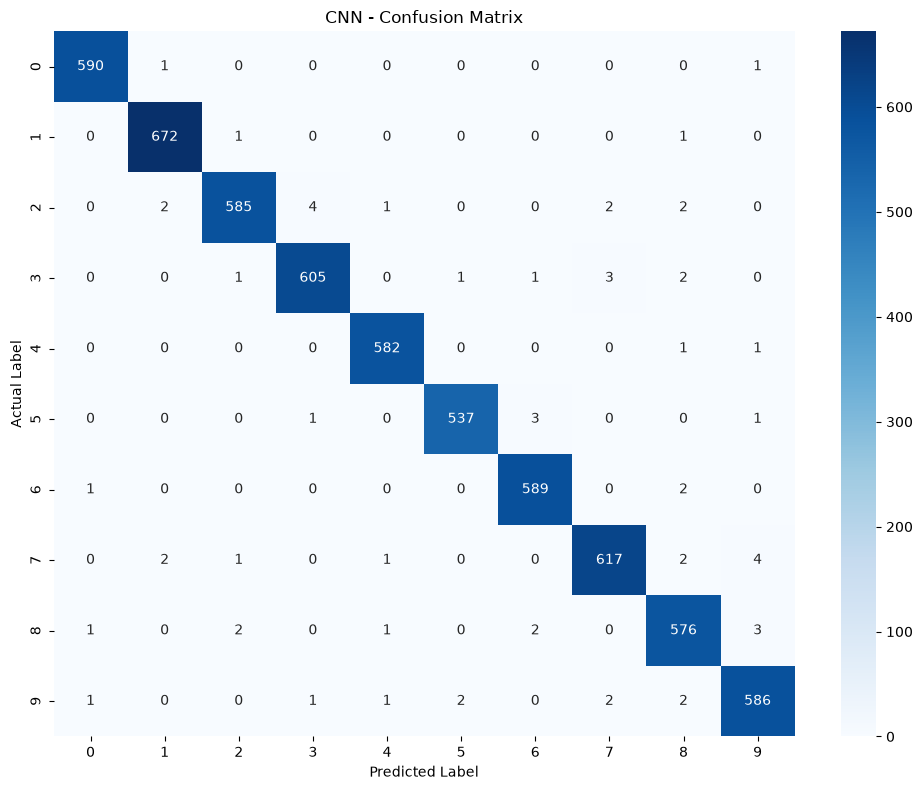

In [83]:
cnn_cm = confusion_matrix(y_val_cnn, y_val_pred_cnn)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("CNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [84]:
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": lr_accuracy,
        "Precision": lr_precision,
        "Recall": lr_recall,
        "F1 Score": lr_f1
    },
    {
        "Model": "KNN",
        "Accuracy": knn_accuracy,
        "Precision": knn_precision,
        "Recall": knn_recall,
        "F1 Score": knn_f1
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1 Score": rf_f1
    },
    {
        "Model": "ANN",
        "Accuracy": ann_accuracy,
        "Precision": ann_precision,
        "Recall": ann_recall,
        "F1 Score": ann_f1
    },
    {
        "Model": "CNN",
        "Accuracy": cnn_accuracy,
        "Precision": cnn_precision,
        "Recall": cnn_recall,
        "F1 Score": cnn_f1
    }
])

model_comparison = model_comparison.sort_values(
    by="Accuracy",
    ascending=False
)

model_comparison.to_csv(
    RESULTS_DIR / "model_comparison.csv",
    index=False
)

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
4,CNN,0.989833,0.989839,0.989833,0.989830
3,ANN,0.973667,0.973783,0.973667,0.973667
1,KNN,0.972333,0.972527,0.972333,0.972290
2,Random Forest,0.965833,0.965861,0.965833,0.965820
0,Logistic Regression,0.922167,0.922020,0.922167,0.922011


In [85]:
cnn_model.save(
    PROJECT_DIR / "models" / "cnn_model.keras"
)

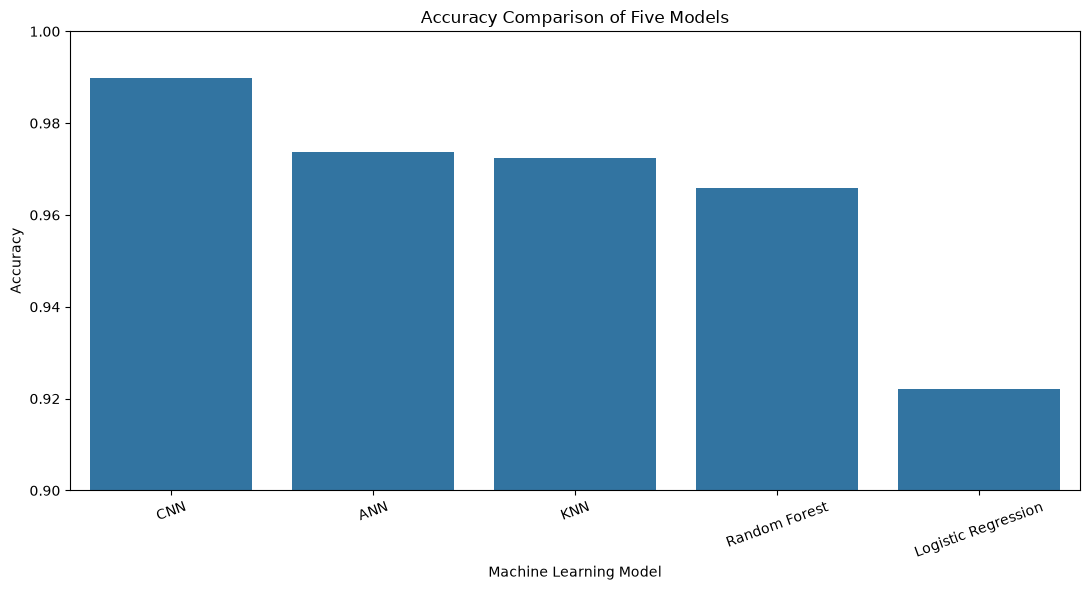

In [86]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Five Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0.90, 1.0)
plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "model_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

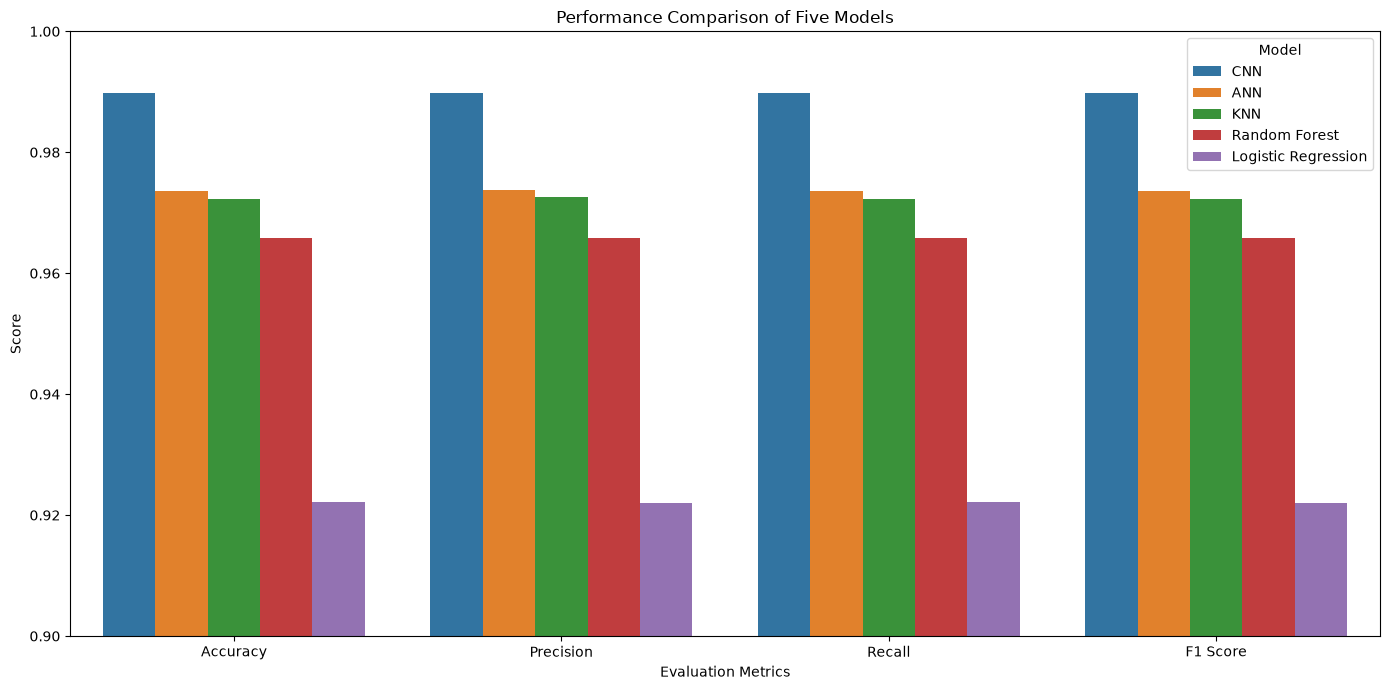

In [87]:
comparison_melted = model_comparison.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=comparison_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Performance Comparison of Five Models")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0.90, 1.0)
plt.legend(title="Model")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "all_metrics_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

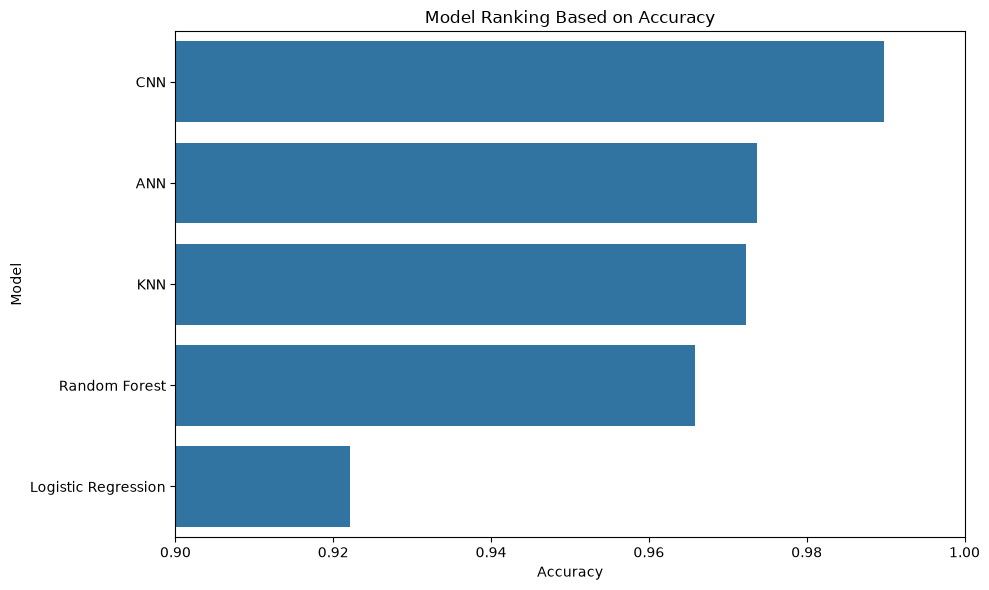

In [88]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_comparison,
    x="Accuracy",
    y="Model"
)

plt.title("Model Ranking Based on Accuracy")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.xlim(0.90, 1.0)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "model_ranking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [89]:
test_inputs = {
    "Logistic Regression": X_test_normalized,
    "KNN": X_test_normalized,
    "Random Forest": X_test_normalized,
    "ANN": X_test_normalized,
    "CNN": X_test_cnn
}

trained_models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Random Forest": rf_model,
    "ANN": ann_model,
    "CNN": cnn_model
}

In [90]:
test_results = []

for model_name, model in trained_models.items():
    predictions = model.predict(test_inputs[model_name])

    if model_name in ["ANN", "CNN"]:
        predictions = np.argmax(predictions, axis=1)

    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="weighted"),
        "Recall": recall_score(y_test, predictions, average="weighted"),
        "F1 Score": f1_score(y_test, predictions, average="weighted")
    })

test_model_comparison = pd.DataFrame(test_results)

test_model_comparison = test_model_comparison.sort_values(
    by="Accuracy",
    ascending=False
)

test_model_comparison

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 742us/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


,Model,Accuracy,Precision,Recall,F1 Score
4,CNN,0.9899,0.989925,0.9899,0.989901
3,ANN,0.9762,0.976328,0.9762,0.976195
1,KNN,0.9709,0.971034,0.9709,0.970868
2,Random Forest,0.9696,0.969612,0.9696,0.969585
0,Logistic Regression,0.9243,0.924110,0.9243,0.924102


In [91]:
test_model_comparison.to_csv(
    RESULTS_DIR / "test_model_comparison.csv",
    index=False
)

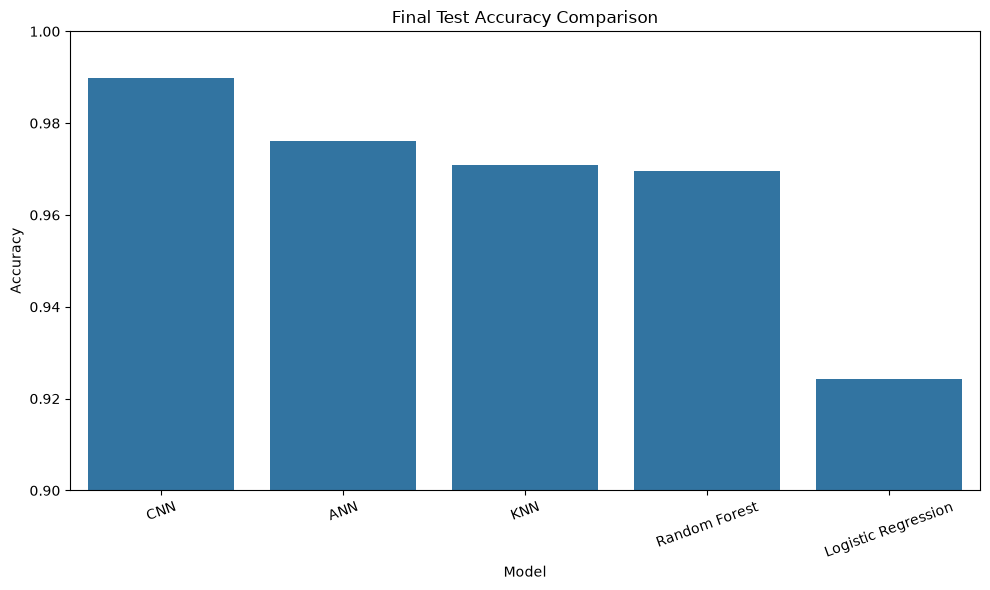

In [92]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=test_model_comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Final Test Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0.90, 1.0)
plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "final_test_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

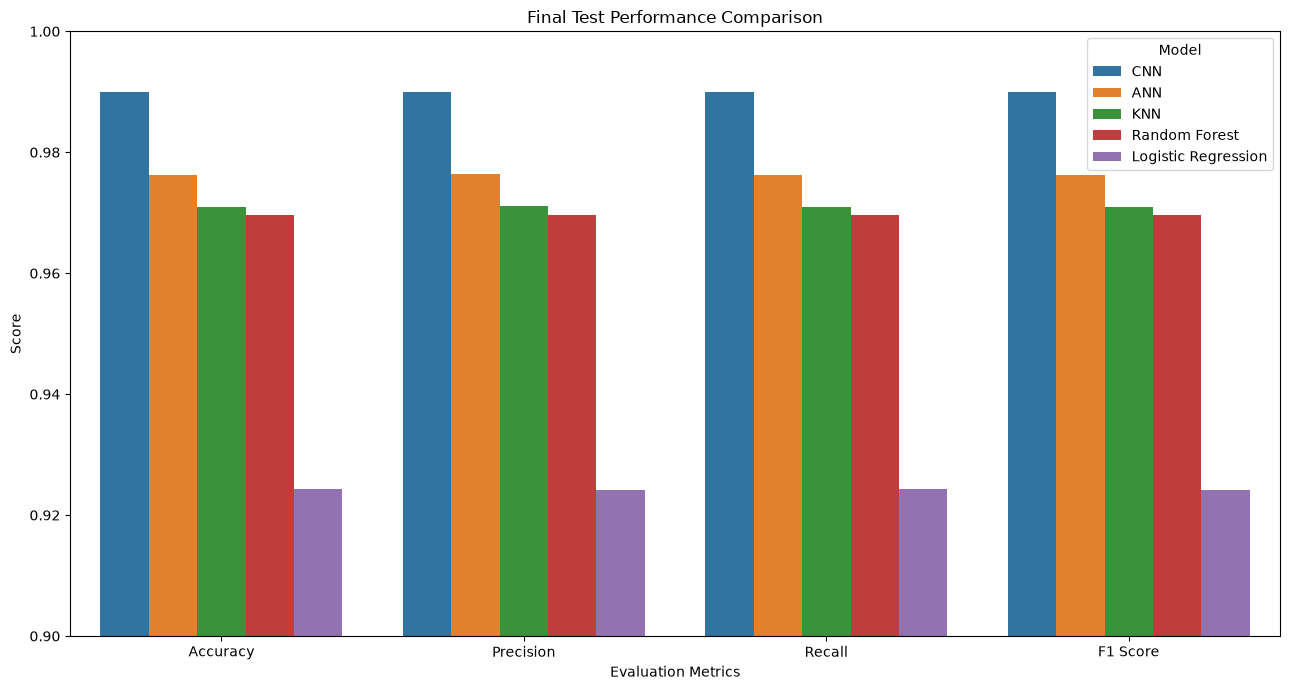

In [93]:
test_comparison_melted = test_model_comparison.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=test_comparison_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Final Test Performance Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0.90, 1.0)
plt.legend(title="Model")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "final_test_all_metrics_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [94]:
best_model_row = test_model_comparison.iloc[0]

print("Best Model:", best_model_row["Model"])
print("Test Accuracy:", best_model_row["Accuracy"])
print("Test F1 Score:", best_model_row["F1 Score"])

Best Model: CNN
Test Accuracy: 0.9899
Test F1 Score: 0.9899008431867098


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


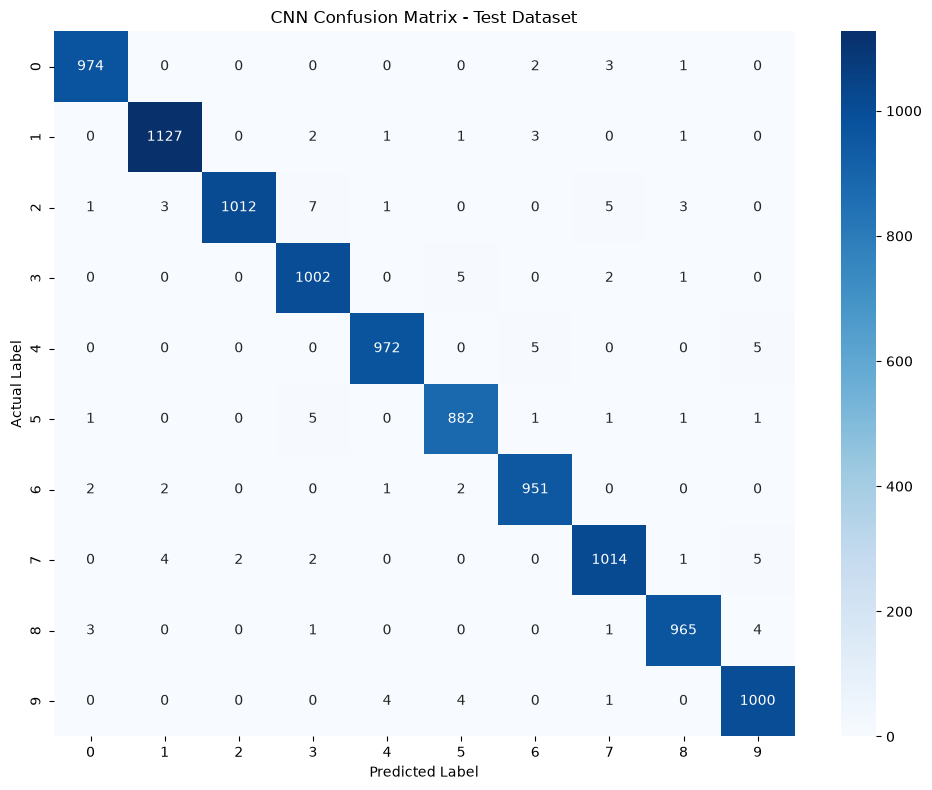

In [96]:
y_test_pred_cnn_prob = cnn_model.predict(X_test_cnn)
y_test_pred_cnn = np.argmax(y_test_pred_cnn_prob, axis=1)
cnn_test_cm = confusion_matrix(y_test, y_test_pred_cnn)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cnn_test_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("CNN Confusion Matrix - Test Dataset")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "cnn_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [97]:
cnn_test_report = classification_report(
    y_test,
    y_test_pred_cnn,
    output_dict=True
)

cnn_test_report_df = pd.DataFrame(cnn_test_report).transpose()

cnn_test_report_df.to_csv(
    RESULTS_DIR / "cnn_test_classification_report.csv"
)

cnn_test_report_df

,precision,recall,f1-score,support
0,0.992864,0.993878,0.993371,980.0000
1,0.992077,0.992952,0.992514,1135.0000
2,0.998028,0.980620,0.989247,1032.0000
3,0.983317,0.992079,0.987679,1010.0000
4,0.992850,0.989817,0.991331,982.0000
5,0.986577,0.988789,0.987682,892.0000
6,0.988565,0.992693,0.990625,958.0000
7,0.987342,0.986381,0.986861,1028.0000
8,0.991778,0.990760,0.991269,974.0000
9,0.985222,0.991080,0.988142,1009.0000


In [98]:
wrong_indices = np.where(y_test != y_test_pred_cnn)[0]

print("Total Test Images:", len(y_test))
print("Correct Predictions:", len(y_test) - len(wrong_indices))
print("Incorrect Predictions:", len(wrong_indices))
print("Test Accuracy:", accuracy_score(y_test, y_test_pred_cnn))

Total Test Images: 10000
Correct Predictions: 9899
Incorrect Predictions: 101
Test Accuracy: 0.9899


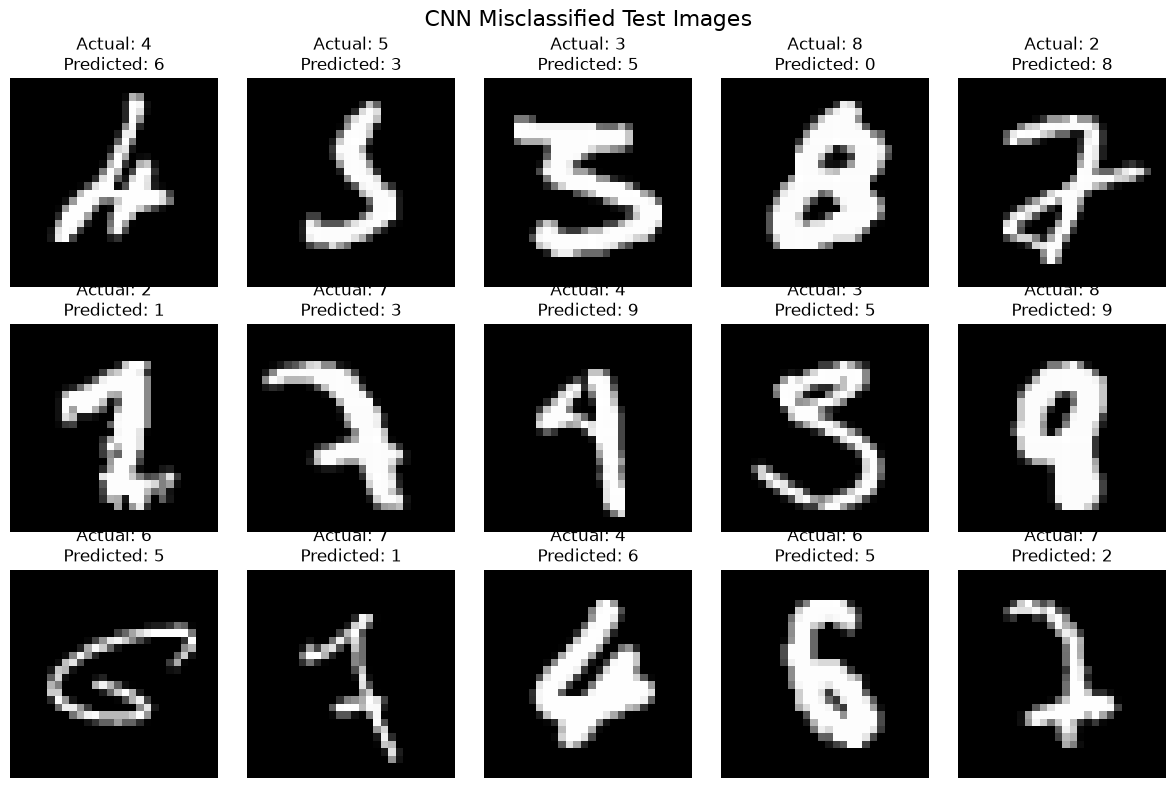

In [99]:
plt.figure(figsize=(12, 8))

for i, index in enumerate(wrong_indices[:15]):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test[index], cmap="gray")

    plt.title(
        f"Actual: {y_test[index]}\nPredicted: {y_test_pred_cnn[index]}"
    )

    plt.axis("off")

plt.suptitle("CNN Misclassified Test Images", fontsize=16)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "cnn_misclassified_samples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [100]:
misclassified_pairs = pd.DataFrame({
    "Actual": y_test[wrong_indices],
    "Predicted": y_test_pred_cnn[wrong_indices]
})

error_counts = (
    misclassified_pairs
    .groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

error_counts.head(10)

,Actual,Predicted,Count
10,2,3,7
17,4,6,5
33,7,9,5
20,5,3,5
18,4,9,5
12,2,7,5
14,3,5,5
29,7,1,4
38,9,4,4
37,8,9,4


In [101]:
error_counts = error_counts.rename(columns={
    "Actual": "Actual Digit",
    "Predicted": "Predicted Digit"
})

error_counts = error_counts.sort_values(
    by=["Count", "Actual Digit"],
    ascending=[False, True]
).reset_index(drop=True)

error_counts.head(10)

,Actual Digit,Predicted Digit,Count
0,2,3,7
1,2,7,5
2,3,5,5
3,4,6,5
4,4,9,5
5,5,3,5
6,7,9,5
7,7,1,4
8,8,9,4
9,9,4,4


In [102]:
error_counts.to_csv(
    RESULTS_DIR / "cnn_misclassification_analysis.csv",
    index=False
)

In [106]:
detailed_errors = pd.DataFrame({
    "Image Index": wrong_indices,
    "Actual Digit": y_test[wrong_indices],
    "Predicted Digit": y_test_pred_cnn[wrong_indices],
    "Confidence": np.max(
        y_test_pred_cnn_prob[wrong_indices],
        axis=1
    )
})

detailed_errors = detailed_errors.sort_values(
    by="Image Index"
).reset_index(drop=True)

print("Number of misclassified images:", len(detailed_errors))

detailed_errors.head()

Number of misclassified images: 101


,Image Index,Actual Digit,Predicted Digit,Confidence
0,247,4,6,0.872108
1,340,5,3,0.612383
2,449,3,5,0.812073
3,495,8,0,0.445026
4,583,2,8,0.492791


In [108]:
detailed_errors.to_csv(
    RESULTS_DIR / "cnn_detailed_misclassifications.csv",
    index=False
)

In [109]:
digit_report = classification_report(
    y_test,
    y_test_pred_cnn,
    labels=list(range(10)),
    output_dict=True
)

digit_performance = pd.DataFrame(digit_report).transpose()

digit_performance = digit_performance.loc[
    [str(i) for i in range(10)],
    ["precision", "recall", "f1-score", "support"]
]

digit_performance.index.name = "Digit"

digit_performance

,precision,recall,f1-score,support
Digit,,,,
0,0.992864,0.993878,0.993371,980.0
1,0.992077,0.992952,0.992514,1135.0
2,0.998028,0.980620,0.989247,1032.0
3,0.983317,0.992079,0.987679,1010.0
4,0.992850,0.989817,0.991331,982.0
5,0.986577,0.988789,0.987682,892.0
6,0.988565,0.992693,0.990625,958.0
7,0.987342,0.986381,0.986861,1028.0
8,0.991778,0.990760,0.991269,974.0


In [110]:
digit_performance.to_csv(
    RESULTS_DIR / "cnn_digit_performance.csv"
)

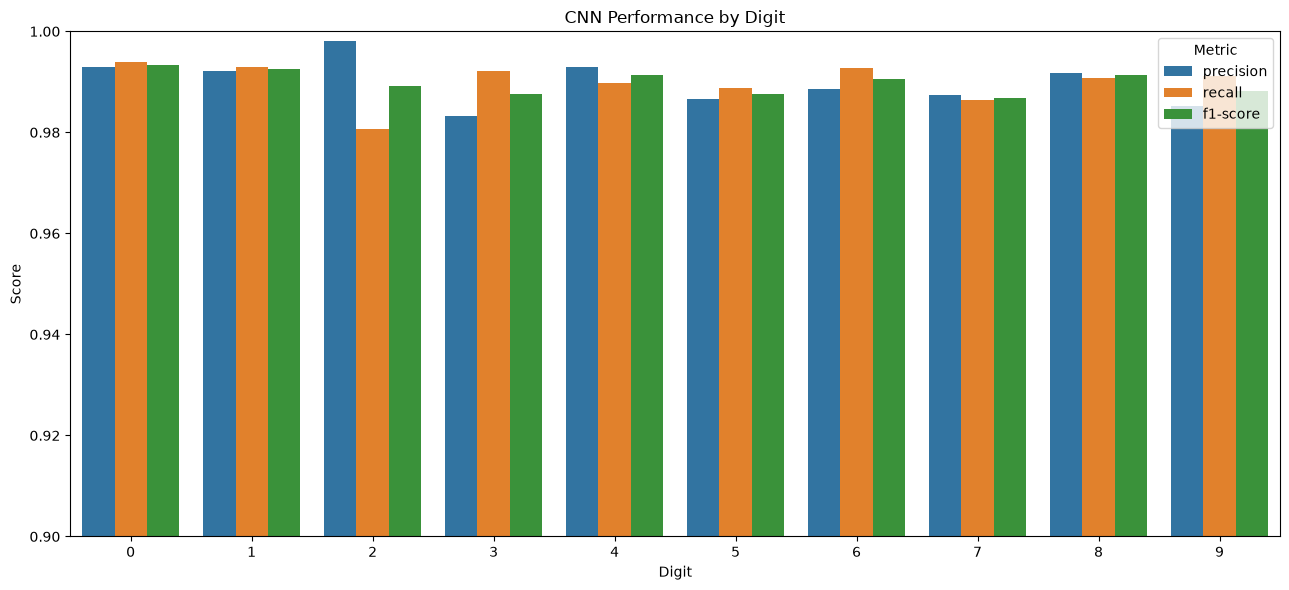

In [111]:
digit_plot_data = digit_performance.reset_index().melt(
    id_vars="Digit",
    value_vars=["precision", "recall", "f1-score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=digit_plot_data,
    x="Digit",
    y="Score",
    hue="Metric"
)

plt.title("CNN Performance by Digit")
plt.xlabel("Digit")
plt.ylabel("Score")
plt.ylim(0.90, 1.0)
plt.legend(title="Metric")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "cnn_digit_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [112]:
weakest_digits = digit_performance.sort_values(
    by="f1-score",
    ascending=True
).head(2)

weakest_digits

,precision,recall,f1-score,support
Digit,,,,
7,0.987342,0.986381,0.986861,1028.0
3,0.983317,0.992079,0.987679,1010.0


In [113]:
weakest_digits.to_csv(
    RESULTS_DIR / "cnn_weakest_digits.csv"
)

In [114]:
digit_errors = detailed_errors[
    detailed_errors["Actual Digit"].isin([2, 7])
]

digit_errors.groupby(
    ["Actual Digit", "Predicted Digit"]
).size().reset_index(name="Count").sort_values(
    "Count",
    ascending=False
)

,Actual Digit,Predicted Digit,Count
2,2,3,7
10,7,9,5
4,2,7,5
6,7,1,4
1,2,1,3
5,2,8,3
8,7,3,2
7,7,2,2
0,2,0,1
3,2,4,1


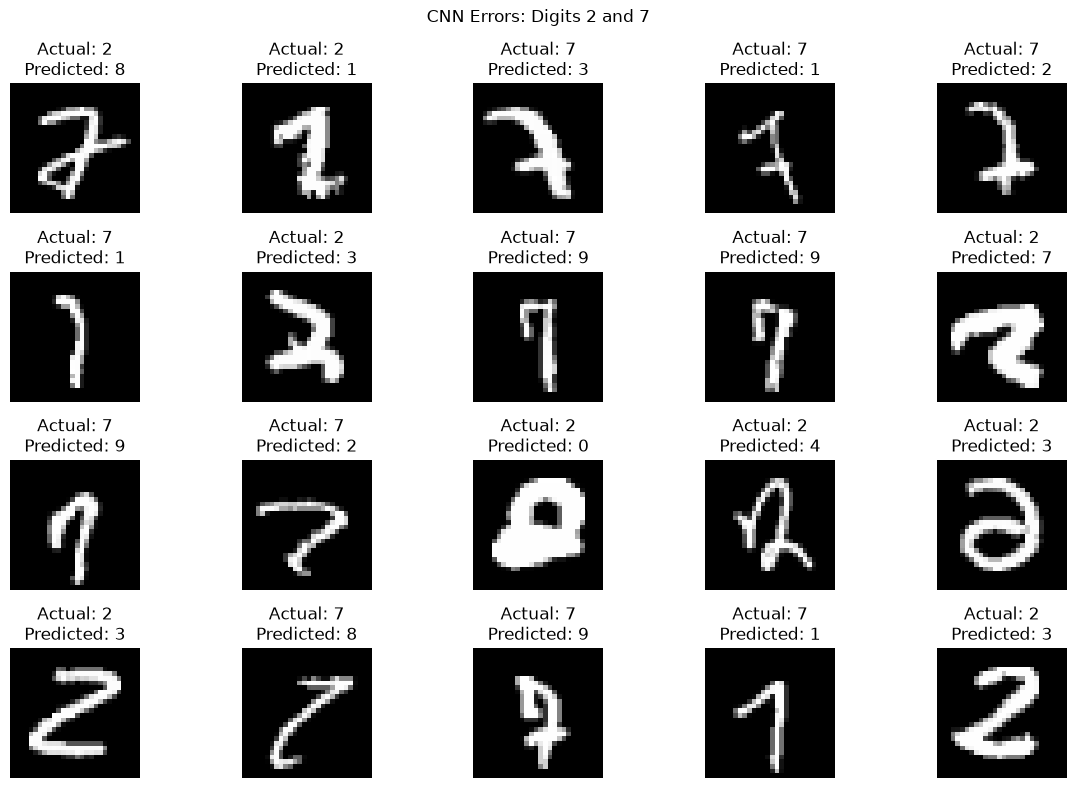

In [115]:
selected_errors = detailed_errors[
    detailed_errors["Actual Digit"].isin([2, 7])
]

plt.figure(figsize=(12, 8))

for i, row in enumerate(selected_errors.head(20).itertuples()):
    index = row[1]

    plt.subplot(4, 5, i + 1)
    plt.imshow(X_test[index], cmap="gray")

    plt.title(
        f"Actual: {y_test[index]}\nPredicted: {y_test_pred_cnn[index]}"
    )

    plt.axis("off")

plt.suptitle("CNN Errors: Digits 2 and 7")
plt.tight_layout()
plt.show()

In [117]:
detailed_errors["Confidence_Percent"] = (
    detailed_errors["Confidence"] * 100
)

detailed_errors[
    [
        "Image Index",
        "Actual Digit",
        "Predicted Digit",
        "Confidence_Percent"
    ]
].sort_values(
    "Confidence_Percent",
    ascending=False
).head(15)

,Image Index,Actual Digit,Predicted Digit,Confidence_Percent
97,9729,5,6,99.986496
54,3520,6,4,99.984619
66,4176,2,7,99.921974
45,2654,6,1,99.861351
25,1549,4,6,99.770889
62,3941,4,6,99.448463
87,6597,0,7,99.253181
96,9664,2,7,98.900261
72,4350,2,3,98.833618
65,4100,2,3,98.786896


In [119]:
wrong_confidence = np.max(
    y_test_pred_cnn_prob[wrong_indices],
    axis=1
)

correct_indices = np.where(y_test == y_test_pred_cnn)[0]

correct_confidence = np.max(
    y_test_pred_cnn_prob[correct_indices],
    axis=1
)

print("Average confidence on correct predictions:",
      np.mean(correct_confidence))

print("Average confidence on incorrect predictions:",
      np.mean(wrong_confidence))

Average confidence on correct predictions: 0.9955224
Average confidence on incorrect predictions: 0.7547768


In [120]:
cnn_model.save(
    PROJECT_DIR / "models" / "cnn_baseline.keras"
)

print("Baseline CNN saved successfully.")

Baseline CNN saved successfully.


In [121]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomTranslation(
        height_factor=0.08,
        width_factor=0.08
    ),
    tf.keras.layers.RandomZoom(0.08)
])

In [122]:
augmented_cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    data_augmentation,

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(10, activation="softmax")
])

augmented_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [123]:
augmented_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [124]:
augmented_history = augmented_cnn.fit(
    X_train_cnn_split,
    y_train_cnn_split,
    validation_data=(X_val_cnn, y_val_cnn),
    epochs=15,
    batch_size=128,
    callbacks=[augmented_early_stopping],
    verbose=1
)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.8169 - loss: 0.5740 - val_accuracy: 0.9708 - val_loss: 0.0979
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9304 - loss: 0.2267 - val_accuracy: 0.9810 - val_loss: 0.0712
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9466 - loss: 0.1727 - val_accuracy: 0.9798 - val_loss: 0.0689
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9552 - loss: 0.1471 - val_accuracy: 0.9845 - val_loss: 0.0547
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.9609 - loss: 0.1281 - val_accuracy: 0.9837 - val_loss: 0.0548
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9654 - loss: 0.1159 - val_accuracy: 0.9853 - val_loss: 0.0527
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9689 - loss: 0.1056 - val_accuracy: 0.9862 - val_loss: 0.0434
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9704 - loss: 0.0979 - val_

In [125]:
baseline_val_loss, baseline_val_accuracy = cnn_model.evaluate(
    X_val_cnn,
    y_val_cnn,
    verbose=0
)

augmented_val_loss, augmented_val_accuracy = augmented_cnn.evaluate(
    X_val_cnn,
    y_val_cnn,
    verbose=0
)

validation_comparison = pd.DataFrame([
    {
        "Model": "Baseline CNN",
        "Validation Accuracy": baseline_val_accuracy,
        "Validation Loss": baseline_val_loss
    },
    {
        "Model": "CNN with Data Augmentation",
        "Validation Accuracy": augmented_val_accuracy,
        "Validation Loss": augmented_val_loss
    }
])

validation_comparison

,Model,Validation Accuracy,Validation Loss
0,Baseline CNN,0.989833,0.039056
1,CNN with Data Augmentation,0.986833,0.041587


In [126]:
augmented_cnn.save(
    PROJECT_DIR / "models" / "augmented_cnn.keras"
)

In [127]:
validation_comparison.to_csv(
    RESULTS_DIR / "cnn_augmentation_validation_comparison.csv",
    index=False
)

In [128]:
improved_cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Dense(10, activation="softmax")
])

improved_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [129]:
improved_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [130]:
improved_history = improved_cnn.fit(
    X_train_cnn_split,
    y_train_cnn_split,
    validation_data=(X_val_cnn, y_val_cnn),
    epochs=15,
    batch_size=128,
    callbacks=[improved_early_stopping],
    verbose=1
)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 31s 71ms/step - accuracy: 0.9413 - loss: 0.1945 - val_accuracy: 0.9025 - val_loss: 0.3060
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 69ms/step - accuracy: 0.9778 - loss: 0.0769 - val_accuracy: 0.9830 - val_loss: 0.0579
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 30s 70ms/step - accuracy: 0.9835 - loss: 0.0546 - val_accuracy: 0.9818 - val_loss: 0.0625
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 68ms/step - accuracy: 0.9866 - loss: 0.0442 - val_accuracy: 0.9827 - val_loss: 0.0652
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 69ms/step - accuracy: 0.9881 - loss: 0.0374 - val_accuracy: 0.9847 - val_loss: 0.0505
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 69ms/step - accuracy: 0.9902 - loss: 0.0323 - val_accuracy: 0.9895 - val_loss: 0.0473
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 30s 70ms/step - accuracy: 0.9911 - loss: 0.0291 - val_accuracy: 0.9868 - val_loss: 0.0559
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 68ms/step - accuracy: 0.9916 - loss: 0.0258 - 

In [131]:
improved_val_loss, improved_val_accuracy = improved_cnn.evaluate(
    X_val_cnn,
    y_val_cnn,
    verbose=0
)

print("Improved CNN Validation Accuracy:", improved_val_accuracy)
print("Improved CNN Validation Loss:", improved_val_loss)

Improved CNN Validation Accuracy: 0.9894999861717224
Improved CNN Validation Loss: 0.04730533808469772


In [132]:
all_cnn_experiments = pd.DataFrame([
    {
        "Model": "Baseline CNN",
        "Validation Accuracy": baseline_val_accuracy,
        "Validation Loss": baseline_val_loss
    },
    {
        "Model": "CNN with Data Augmentation",
        "Validation Accuracy": augmented_val_accuracy,
        "Validation Loss": augmented_val_loss
    },
    {
        "Model": "Improved CNN",
        "Validation Accuracy": improved_val_accuracy,
        "Validation Loss": improved_val_loss
    }
])

all_cnn_experiments = all_cnn_experiments.sort_values(
    by="Validation Accuracy",
    ascending=False
).reset_index(drop=True)

all_cnn_experiments

,Model,Validation Accuracy,Validation Loss
0,Baseline CNN,0.989833,0.039056
1,Improved CNN,0.989500,0.047305
2,CNN with Data Augmentation,0.986833,0.041587


In [133]:
improved_cnn.save(
    PROJECT_DIR / "models" / "improved_cnn.keras"
)

all_cnn_experiments.to_csv(
    RESULTS_DIR / "cnn_experiments_comparison.csv",
    index=False
)

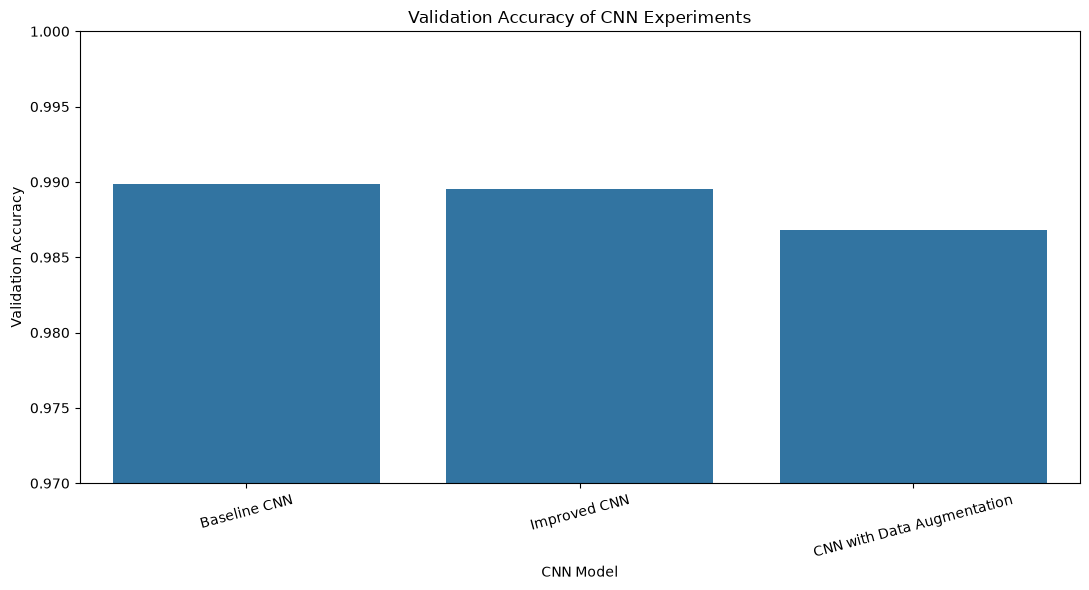

In [136]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=all_cnn_experiments,
    x="Model",
    y="Validation Accuracy"
)

plt.title("Validation Accuracy of CNN Experiments")
plt.xlabel("CNN Model")
plt.ylabel("Validation Accuracy")
plt.ylim(0.97, 1.0)
plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "cnn_experiments_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [134]:
final_model = cnn_model

final_model_name = "Baseline CNN"

final_model_summary = pd.DataFrame([{
    "Selected Model": final_model_name,
    "Validation Accuracy": baseline_val_accuracy,
    "Validation Loss": baseline_val_loss,
    "Test Accuracy": cnn_accuracy,
    "Test F1 Score": cnn_f1
}])

final_model_summary

,Selected Model,Validation Accuracy,Validation Loss,Test Accuracy,Test F1 Score
0,Baseline CNN,0.989833,0.039056,0.989833,0.98983


In [135]:
final_model.save(
    PROJECT_DIR / "models" / "final_mnist_cnn.keras"
)

final_model_summary.to_csv(
    RESULTS_DIR / "final_model_summary.csv",
    index=False
)